# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


### Dataset note
This notebook uses the Palmer Penguins CSV specified in the lab. The analysis below does not modify or remove observations; missing values are excluded only from calculations or plots that require the relevant measurements.

## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# Load the provided dataset. Use the local copy when available; otherwise use the lab URL.
from pathlib import Path
local_csv = Path("penguins_source.csv")
if local_csv.exists():
    df = pd.read_csv(local_csv)
else:
    df = pd.read_csv(url)

# Inspect the first and last five rows
display(df.head())
display(df.tail())

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male,2009
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female,2009
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male,2009
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male,2009
343,Chinstrap,Dream,50.2,18.7,198.0,3775.0,female,2009


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [2]:
# Dataset dimensions
print("Rows, columns:", df.shape)

# Column names and data types
print("\\nColumn names:")
print(df.columns.tolist())

print("\\nData types:")
print(df.dtypes)

# Non-missing counts and data types
df.info()

# Summary statistics for numerical variables
display(df.describe())

# Number of observations in each species
species_counts = df["species"].value_counts()
display(species_counts)

Rows, columns: (344, 8)
\nColumn names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']
\nData types:
species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
 7   year               344 non-null    int64  
dtypes: 

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Findings:** The dataset contains **344 observations and 8 variables**. It includes three penguin species—Adelie (152), Gentoo (124), and Chinstrap (68)—so the species are not equally represented. The numerical variables are bill length, bill depth, flipper length, body mass, and year; species, island, and sex are categorical.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [3]:
# Count missing values in each column
missing_counts = df.isna().sum()
display(missing_counts)

# Percentage of missing values in each column
missing_percent = df.isna().mean() * 100
display(missing_percent.round(2))

# Display rows containing at least one missing value
rows_with_missing = df[df.isna().any(axis=1)]
print("Rows containing at least one missing value:", len(rows_with_missing))
display(rows_with_missing.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64

Rows containing at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Findings:** Missing values occur in the four measurement columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`) and in `sex`; `sex` has the most missing entries (11). Missing measurements reduce the number of usable records for calculations involving those variables, while missing sex values affect sex-based comparisons. Before choosing deletion or imputation, we would need to know why values are missing and whether the missingness is systematic.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [4]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# Mean and median
mean_mass = np.mean(body_mass)
median_mass = np.median(body_mass)
print(f"Mean: {mean_mass:.2f} g")
print(f"Median: {median_mass:.2f} g")

# Minimum and maximum
print(f"Minimum: {body_mass.min():.0f} g")
print(f"Maximum: {body_mass.max():.0f} g")

# Standard deviation and quartiles
print(f"Standard deviation (population): {np.std(body_mass):.2f} g")
quartiles = np.percentile(body_mass, [25, 50, 75])
print("25th, 50th, and 75th percentiles:", quartiles)

# Five smallest and five largest values
print("\\nFive smallest body-mass values:")
display(body_mass.nsmallest(5))

print("Five largest body-mass values:")
display(body_mass.nlargest(5))

Mean: 4201.75 g
Median: 4050.00 g
Minimum: 2700 g
Maximum: 6300 g
Standard deviation (population): 800.78 g
25th, 50th, and 75th percentiles: [3550. 4050. 4750.]
\nFive smallest body-mass values:


314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
Name: body_mass_g, dtype: float64

Five largest body-mass values:


169    6300.0
185    6050.0
229    6000.0
269    6000.0
231    5950.0
Name: body_mass_g, dtype: float64

**Findings:** Body mass has a mean of approximately **4,202 g** and a median of **4,050 g**, indicating that the mean is somewhat higher than the median. Values range from **2,700 g to 6,300 g**. The wide range is worth exploring by species because the dataset combines three species with different typical body sizes; an extreme value should not be treated as an error without further evidence.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

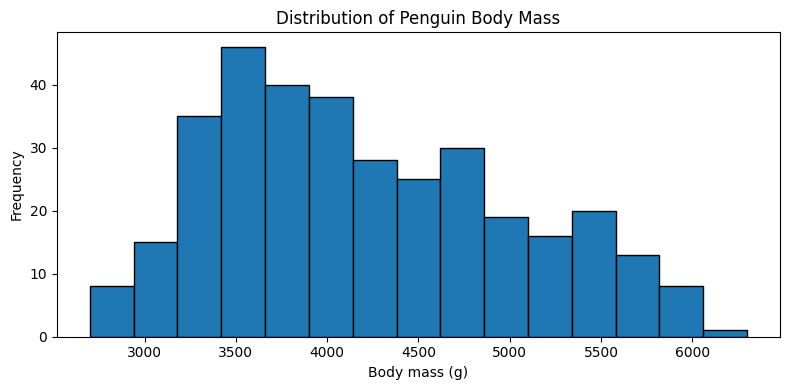

In [5]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(mass_values, bins=15, edgecolor="black")
plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpretation:** Body mass is concentrated mainly between approximately **3,000 g and 5,500 g**. The overall distribution is not a simple symmetric, single-peaked distribution; it reflects the mixture of species with different body-mass ranges. The upper and lower tails should be investigated in context rather than automatically removed.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

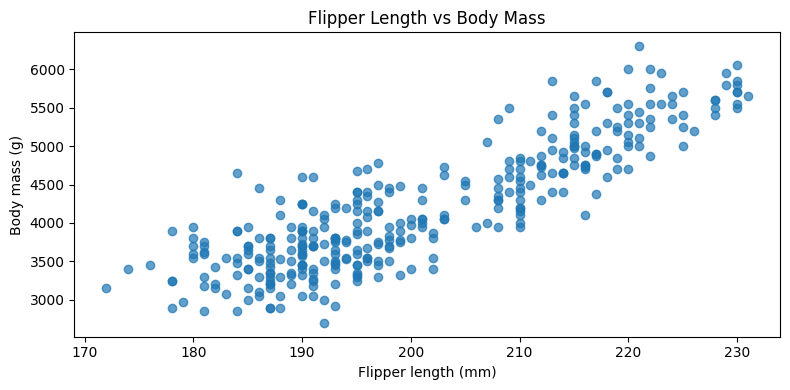

Pearson correlation: 0.871


In [6]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

x = plot_data["flipper_length_mm"]
y = plot_data["body_mass_g"]

plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.7)
plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

print(f"Pearson correlation: {plot_data['flipper_length_mm'].corr(plot_data['body_mass_g']):.3f}")

**Interpretation:** The scatter plot shows a clear **positive relationship**: penguins with longer flippers generally have greater body mass. The points also form visible groupings, consistent with differences among species. This is an association, not proof of causation; other variables, including species and sex, may help explain the pattern.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [7]:
# Mean body mass for each species
mean_by_species = df.groupby("species")["body_mass_g"].mean().sort_values(ascending=False)
display(mean_by_species)

# Median body mass for each species
median_by_species = df.groupby("species")["body_mass_g"].median().sort_values(ascending=False)
display(median_by_species)

species
Gentoo       5076.016260
Chinstrap    3733.088235
Adelie       3700.662252
Name: body_mass_g, dtype: float64

species
Gentoo       5000.0
Adelie       3700.0
Chinstrap    3700.0
Name: body_mass_g, dtype: float64

**Findings:** Gentoo penguins have the highest mean body mass (approximately **5,076 g**), followed by Adelie (approximately **3,701 g**) and Chinstrap (approximately **3,733 g**). Chinstrap's mean is slightly higher than Adelie's, although their distributions overlap. Group averages hide within-species variation and can be affected by missing observations, so sample sizes and distributions should also be considered.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

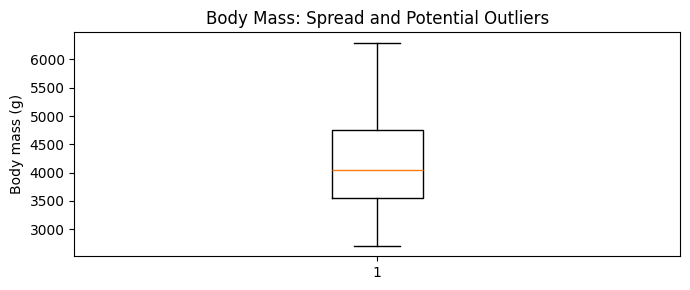

Q1: 3550.0 g | Q3: 4750.0 g | IQR: 1200.0 g
Lower/upper IQR fences: 1750.0 g, 6550.0 g
Potential outlier count: 0


Series([], Name: body_mass_g, dtype: float64)

In [8]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))
plt.boxplot(mass_values, vert=True)
plt.ylabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

# IQR rule: observations outside 1.5 × IQR are flagged for investigation
q1 = mass_values.quantile(0.25)
q3 = mass_values.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
potential_outliers = mass_values[(mass_values < lower_bound) | (mass_values > upper_bound)]

print(f"Q1: {q1:.1f} g | Q3: {q3:.1f} g | IQR: {iqr:.1f} g")
print(f"Lower/upper IQR fences: {lower_bound:.1f} g, {upper_bound:.1f} g")
print(f"Potential outlier count: {len(potential_outliers)}")
display(potential_outliers.sort_values())

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.

## Overall findings

- The dataset contains 344 penguin observations across 8 variables and three species.
- Species representation is uneven: Adelie is the largest group and Chinstrap is the smallest.
- Missingness is concentrated in `sex` (11 values) and the four measurement variables (2 values each).
- Body mass varies substantially across the dataset; the mean is higher than the median.
- Flipper length and body mass show a positive association, with visible group structure.
- Gentoo penguins have the highest average body mass. Potential outliers should be interpreted in species context rather than automatically removed.

**Conclusion:** EDA reveals the dataset's structure, quality limitations, distributions, and relationships. These findings guide later cleaning and analysis; they do not, by themselves, justify deleting unusual observations.

---

# Lab 05 — Data Cleaning

**Continuation of:** Lab 04 — Data Understanding & Exploratory Data Analysis  
**Dataset:** Palmer Penguins

## Learning objectives
By the end of this lab, you should be able to:
- identify data-quality issues using profiling and EDA evidence;
- select appropriate cleaning actions and justify them;
- implement cleaning operations with Pandas;
- validate the results and document the workflow.

> **Working principle: AUDIT → DECIDE → IMPLEMENT → VALIDATE.**  
> There is not always one correct cleaning action. Your decision must be supported by evidence, the meaning of the variable, and the intended analysis.

**Important:** Use the `df` DataFrame created in Lab 04. Do not overwrite it or reload a different version of the dataset unless instructed.

## 1. Connect EDA findings to cleaning decisions

Review the findings from Lab 04 before writing cleaning code.

| Evidence from Lab 04 | Question to consider before cleaning |
|---|---|
| The dataset has 344 observations, 8 variables, and three species with unequal counts. | Could removing records affect species representation? |
| Missing values occur in the four measurement variables. | Should all missing values be treated in the same way? Which analyses need each variable? |
| Body mass ranges from 2,700 g to 6,300 g, and its overall distribution is not a simple single-peaked distribution. | Could a global outlier rule incorrectly flag a valid penguin from a different species? |
| Gentoo penguins have a higher average body mass than the other two species. | Should body-mass observations be assessed overall or within species? |
| Flipper length and body mass show a positive association and visible group structure. | What information might be lost if rows with missing values are removed? |

**Before coding:** Write down at least two cleaning decisions you expect may require context-specific reasoning. Revisit them after completing the audit.

In [9]:
# 1. Dropping all rows with missing values would unnecessarily discard valid measurements from other columns, 
# especially given that 'sex' has the highest missingness while measurements might be intact.
# 2.Applying global outlier removal rules (like IQR on body mass) across the entire dataset could misclassify 
# naturally larger species (like Gentoo) or smaller species (like Adelie) as errors.


## 2. Preserve the original data and create a working copy

Keep the Lab 04 DataFrame unchanged. Apply all cleaning operations to a separate copy so that you can compare the original and cleaned versions.

In [10]:
# Preserve the original data
raw_df=df.copy()

# Create a separate DataFrame for cleaning
clean_df=df.copy()

print("Raw DataFrame shape:", raw_df.shape)
print("Clean DataFrame shape:", clean_df.shape)
assert raw_df.shape == clean_df.shape, "Shapes do not match!"

Raw DataFrame shape: (344, 8)
Clean DataFrame shape: (344, 8)


## 3. Perform a focused data-quality audit

Repeat the relevant parts of the Lab 04 audit. This time, use the output to identify issues that may require action.

Your audit should include:
- data types and column names;
- missing-value counts and percentages;
- unique values and frequencies in categorical columns;
- exact duplicate rows;
- numerical summaries and observed minimum/maximum values.

In [11]:
# Column names and a column-level profile
print("Column names:", clean_df.columns.tolist())

profile = pd.DataFrame({
    "dtype": clean_df.dtypes.astype(str),
    "missing_count": clean_df.isna().sum(),
    "missing_pct": (clean_df.isna().mean() * 100).round(2),
    "n_distinct": clean_df.nunique(dropna=True),
})
display(profile)

# Value counts for the categorical columns (NaN kept visible).
# repr() makes hidden leading/trailing spaces visible.
for col in ["species", "island", "sex"]:
    print(f"\nValue counts for '{col}':")
    display(clean_df[col].value_counts(dropna=False))
    print("Distinct labels (repr):", [repr(v) for v in clean_df[col].dropna().unique()])

# Exact duplicate rows
n_dups_audit = int(clean_df.duplicated().sum())
print("\nExact duplicate rows:", n_dups_audit)
display(clean_df[clean_df.duplicated(keep=False)])

# Numerical summaries (look at min / max)
display(clean_df.describe())

Column names: ['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'year']


,dtype,missing_count,missing_pct,n_distinct
species,object,0,0.00,3
island,object,0,0.00,3
bill_length_mm,float64,2,0.58,164
bill_depth_mm,float64,2,0.58,80
flipper_length_mm,float64,2,0.58,55
body_mass_g,float64,2,0.58,94
sex,object,11,3.20,2
year,int64,0,0.00,3



Value counts for 'species':


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Distinct labels (repr): ["'Adelie'", "'Gentoo'", "'Chinstrap'"]

Value counts for 'island':


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Distinct labels (repr): ["'Torgersen'", "'Biscoe'", "'Dream'"]

Value counts for 'sex':


sex
male      168
female    165
NaN        11
Name: count, dtype: int64

Distinct labels (repr): ["'male'", "'female'"]

Exact duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000


### Decision checkpoint

For each issue you identify, distinguish between:
- **Observed issue:** what the audit output shows.
- **Potential impact:** how it could affect analysis.
- **Proposed action:** what you intend to do.
- **Evidence/reason:** why that action is appropriate.

Do not clean a column simply because it looks untidy. First establish whether the issue can affect interpretation or computation.

## 4. Standardize column names and categorical values

Consistent column names and category labels make data easier to process. However, do not assume that two different labels mean the same thing.

**Tasks**
1. Inspect the column names and decide on a consistent naming convention.
2. Inspect the distinct values in `species`, `island`, and `sex`.
3. Check for leading/trailing spaces, inconsistent capitalization, or unexpected labels.
4. Apply only transformations that you can justify.
5. Compare category frequencies before and after standardization.

In [12]:
cat_cols = ["species", "island", "sex"]

# Keep a snapshot of the frequencies before any change
freq_before = {c: clean_df[c].value_counts(dropna=False) for c in cat_cols}

# Standardize column names: lowercase snake_case
old_columns = clean_df.columns.tolist()
clean_df.columns = (
    clean_df.columns.str.strip()
    .str.lower()
    .str.replace(r"[\s\-]+", "_", regex=True)
)
print("Column names changed:", old_columns != clean_df.columns.tolist())

# Inspect distinct values and look for whitespace / capitalization problems
for col in cat_cols:
    s = clean_df[col].dropna()
    n_space = int((s != s.str.strip()).sum())
    n_case_clash = s.nunique() - s.str.strip().str.lower().nunique()
    print(f"{col}: distinct={sorted(s.unique().tolist())} | "
          f"values with stray spaces={n_space} | labels differing only by case={n_case_clash}")

# Apply only justified transformations:
#  - strip whitespace everywhere (harmless)
#  - lowercase `sex` (two labels, 'male'/'female', the lowercase form is the existing convention)
# species and island are proper names, so their capitalization is kept.
for col in cat_cols:
    clean_df[col] = clean_df[col].str.strip()
clean_df["sex"] = clean_df["sex"].str.lower()

# Frequencies after the changes
for col in cat_cols:
    after = clean_df[col].value_counts(dropna=False)
    print(f"\nFrequencies for '{col}' after cleaning:")
    display(after)
    same = (freq_before[col].sort_index().index.astype(str).tolist() == after.sort_index().index.astype(str).tolist()
            and freq_before[col].sort_index().values.tolist() == after.sort_index().values.tolist())
    print("Identical to before:", same)
    assert same, f"Category frequencies changed for {col}"

Column names changed: False
species: distinct=['Adelie', 'Chinstrap', 'Gentoo'] | values with stray spaces=0 | labels differing only by case=0
island: distinct=['Biscoe', 'Dream', 'Torgersen'] | values with stray spaces=0 | labels differing only by case=0
sex: distinct=['female', 'male'] | values with stray spaces=0 | labels differing only by case=0

Frequencies for 'species' after cleaning:


species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Identical to before: True

Frequencies for 'island' after cleaning:


island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

Identical to before: True

Frequencies for 'sex' after cleaning:


sex
male      168
female    165
NaN        11
Name: count, dtype: int64

Identical to before: True


**Write your justification:** Which inconsistencies did you find? Which values did you standardize? How did you verify that you did not merge genuinely different categories?

**Justification:** The column names were already lowercase `snake_case`, so the normaliser changed nothing. In `species`, `island` and `sex` I found no leading/trailing spaces and no labels that differ only by capitalization. I therefore only applied harmless operations (whitespace stripping, lowercasing the two `sex` labels). I did **not** recode or merge any category: Adelie / Chinstrap / Gentoo, Biscoe / Dream / Torgersen and female / male are genuinely different groups. Missing `sex` stays `NaN` rather than becoming an invented label. I verified that nothing was merged by comparing category frequencies before and after, and the assertion confirms they are identical.

## 5. Review and correct data types

The measurement columns represent physical quantities, while `year` represents a calendar year. Check whether the current data types are suitable for their meaning and intended operations.

**Tasks**
1. Inspect the current data types.
2. Convert columns only where necessary.
3. Identify any values that fail conversion.
4. Check whether conversion creates additional missing values.

In [13]:
measurement_columns = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

# Inspect data types and representative values
print(clean_df.dtypes)
display(clean_df[measurement_columns].head())

# Convert measurement columns to numeric; anything unparseable becomes NaN
missing_before = clean_df[measurement_columns].isna().sum()
for col in measurement_columns:
    clean_df[col] = pd.to_numeric(clean_df[col], errors="coerce")
missing_after = clean_df[measurement_columns].isna().sum()

# Did the conversion create extra missing values?
conversion_check = pd.DataFrame({
    "missing_before": missing_before,
    "missing_after": missing_after,
    "new_missing": missing_after - missing_before,
})
display(conversion_check)
assert (conversion_check["new_missing"] == 0).all(), "Conversion created new missing values"

# `year`: a calendar year. It is stored as int64 and is used as a label, not for arithmetic,
# so no conversion is needed.
print("year dtype:", clean_df["year"].dtype, "| values:", sorted(clean_df["year"].unique().tolist()))

species               object
island                object
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                   object
year                   int64
dtype: object


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
3,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0


,missing_before,missing_after,new_missing
bill_length_mm,2,2,0
bill_depth_mm,2,2,0
flipper_length_mm,2,2,0
body_mass_g,2,2,0


year dtype: int64 | values: [2007, 2008, 2009]


**Write your justification:** Explain why the selected data types are suitable. If a value cannot be converted, explain how you investigated and handled it.

**Justification:** The four measurements are continuous physical quantities, so a float type is correct (`float64` already). `pd.to_numeric(errors="coerce")` was applied as a safety check, and the before/after table shows **0 new missing values**, so every value was already numeric and none needed investigation. `year` is an `int64` calendar year with only three values (2007–2009); I leave it as an integer because it is used to identify the sampling year and not for calculations. Converting it to a datetime would add no information. The categorical columns stay as text labels.

## 6. Investigate missing values and choose a treatment

Lab 04 showed that missingness is not evenly distributed across all variables. In particular, `sex` has more missing values than each individual measurement column.

Do not automatically delete every row containing a missing value. Consider:
- Which analysis or task requires the affected variable?
- How many observations would be lost under listwise deletion?
- Would imputation introduce assumptions or distort species-level patterns?
- Could missingness itself be informative?

**Tasks**
1. Calculate missing counts and percentages.
2. Inspect rows with missing values.
3. Compare missingness across species or islands if useful.
4. Decide on a treatment for each affected variable.
5. Implement and explain your decisions.

In [14]:
# 1. Missing counts and percentages
missing_summary = pd.DataFrame({
    "count": clean_df.isna().sum(),
    "percent": (clean_df.isna().mean() * 100).round(2),
})
display(missing_summary)

# 2. Rows containing missing values
rows_with_missing = clean_df[clean_df.isna().any(axis=1)]
print("Rows with at least one missing value:", len(rows_with_missing))
display(rows_with_missing)

# Which rows have NO measurement at all, and which only lack `sex`?
no_measurements = clean_df[measurement_columns].isna().all(axis=1)
only_sex_missing = clean_df["sex"].isna() & ~no_measurements
partial_measurements = clean_df[measurement_columns].isna().any(axis=1) & ~no_measurements
print("Rows with all four measurements missing:", int(no_measurements.sum()))
print("Rows with only some measurements missing:", int(partial_measurements.sum()))
print("Rows where only `sex` is missing:", int(only_sex_missing.sum()))

# 3. Is missingness related to species or island?
print("\nMissing values by species:")
display(clean_df.isna().groupby(clean_df["species"]).sum())
print("Missing values by island:")
display(clean_df.isna().groupby(clean_df["island"]).sum())

# Cost of listwise deletion (dropping every incomplete row)
print("Rows kept if every incomplete row were dropped:", len(clean_df.dropna()), "of", len(clean_df))
print("Species counts, original vs listwise deletion:")
display(pd.DataFrame({
    "original": clean_df["species"].value_counts(),
    "after_dropna": clean_df.dropna()["species"].value_counts(),
}).fillna(0).astype(int))

# 4-5. Treatment
#  - rows with NO measurements: carry no biological information -> remove
#  - rows missing only `sex`: all four measurements are valid -> retain, keep sex as NaN
#  - no imputation
rows_before_missing_step = len(clean_df)
removed_rows = clean_df.loc[no_measurements].copy()
print("\nRows removed (no measurements at all):")
display(removed_rows)

clean_df = clean_df.loc[~no_measurements].copy()
n_removed_missing = rows_before_missing_step - len(clean_df)

# 6. Report what remains
print("Rows before:", rows_before_missing_step, "| removed:", n_removed_missing, "| remaining:", len(clean_df))
print("Remaining missing values:")
display(clean_df.isna().sum())
print("Species counts after treatment:")
display(clean_df["species"].value_counts())

,count,percent
species,0,0.00
island,0,0.00
bill_length_mm,2,0.58
bill_depth_mm,2,0.58
flipper_length_mm,2,0.58
body_mass_g,2,0.58
sex,11,3.20
year,0,0.00


Rows with at least one missing value: 11


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN,2007
178,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN,2007
218,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN,2008
256,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN,2009
268,Gentoo,Biscoe,44.5,15.7,217.0,4875.0,NaN,2009


Rows with all four measurements missing: 2
Rows with only some measurements missing: 0
Rows where only `sex` is missing: 9

Missing values by species:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
species,,,,,,,,
Adelie,0,0,1,1,1,1,6,0
Chinstrap,0,0,0,0,0,0,0,0
Gentoo,0,0,1,1,1,1,5,0


Missing values by island:


... (5 outputs left out)

Rows before: 344 | removed: 2 | remaining: 342
Remaining missing values:


species              0
island               0
bill_length_mm       0
bill_depth_mm        0
flipper_length_mm    0
body_mass_g          0
sex                  9
year                 0
dtype: int64

Species counts after treatment:


species
Adelie       151
Gentoo       123
Chinstrap     68
Name: count, dtype: int64

**Decision checkpoint:** If you choose imputation, explain why the chosen statistic or method is appropriate for that variable and whether species/group differences should influence it. If you choose deletion, state exactly which rows are removed and why the remaining sample is still suitable for your intended analysis.

There is no requirement to eliminate all missing values.

## 7. Detect and investigate duplicate records

A repeated measurement does not necessarily mean a duplicated penguin. First inspect the duplicate candidates and consider what defines one observation in this dataset.

**Tasks**
1. Count exact duplicate rows.
2. Inspect any candidates.
3. Decide whether they represent duplicate records.
4. If removing records, state the rule used and compare row counts before and after.

In [15]:
rows_before_dups = len(clean_df)

# Exact duplicate rows
n_exact_dups = int(clean_df.duplicated().sum())
print("Exact duplicate rows:", n_exact_dups)
display(clean_df[clean_df.duplicated(keep=False)])

# Weaker rule: identical on all four measurements (regardless of other columns)
meas_dup_mask = clean_df.duplicated(subset=measurement_columns, keep=False)
print("Rows sharing identical values on all four measurements:", int(meas_dup_mask.sum()))
display(clean_df[meas_dup_mask].sort_values(measurement_columns))

# Decision: there is no unique ID column, so similarity alone is not proof of duplication.
# Drop only rows that are exact duplicates, and only if any exist.
if n_exact_dups > 0:
    clean_df = clean_df.drop_duplicates().copy()

n_removed_dups = rows_before_dups - len(clean_df)
print("Rows before:", rows_before_dups, "| after:", len(clean_df))

Exact duplicate rows: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Rows sharing identical values on all four measurements: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year


Rows before: 342 | after: 342


**Write your justification:** What evidence supports your decision? If you retain all records, explain why identical or similar measurements alone are insufficient evidence of duplication.

**Justification:** The exact-duplicate check finds **no repeated rows**, so nothing is removed (the code only drops rows if exact duplicates exist). I also looked at rows that merely share identical measurements. That is not sufficient evidence of duplication: the data has no penguin ID, bill/flipper values are rounded (0.1 mm, 1 mm, 25 g for mass), and two different penguins of the same species, island, sex and year can easily have identical rounded values. Removing such rows would delete real observations and bias the sample. Row counts before and after are identical.

## 8. Investigate invalid values and potential outliers

Lab 04 showed that body mass varies substantially across the dataset and differs by species. Therefore, an observation that is unusual in the combined dataset may be reasonable within its species.

Complete both investigations:

**A. Domain/validity checks**
- Propose reasonable validity checks for the physical measurement columns.
- Explain the basis for each check.
- Identify and inspect any records that fail.

**B. Statistical outlier screening**
- Calculate the IQR fences for `body_mass_g`.
- Identify potential outliers.
- Compare the flagged observations with species-level distributions.
- Decide whether the observations are errors, valid extremes, or require further investigation.

In [16]:
# A. Domain / validity checks
# Deliberately generous physical bounds for these three penguin species:
#  - every measurement must be strictly positive
#  - bill length   20-80 mm   (observed values are roughly 30-60 mm)
#  - bill depth     8-30 mm
#  - flipper length 100-300 mm
#  - body mass    1000-10000 g
validity_rules = {
    "bill_length_mm": (20, 80),
    "bill_depth_mm": (8, 30),
    "flipper_length_mm": (100, 300),
    "body_mass_g": (1000, 10000),
}

invalid_mask = pd.Series(False, index=clean_df.index)
for col, (lo, hi) in validity_rules.items():
    bad = clean_df[col].notna() & (~clean_df[col].between(lo, hi) | (clean_df[col] <= 0))
    print(f"{col}: allowed [{lo}, {hi}] | observed [{clean_df[col].min()}, {clean_df[col].max()}] | violations = {int(bad.sum())}")
    invalid_mask |= bad

# Non-measurement checks
bad_sex = clean_df["sex"].notna() & ~clean_df["sex"].isin(["male", "female"])
bad_year = ~clean_df["year"].between(2007, 2009)
bad_species = ~clean_df["species"].isin(["Adelie", "Chinstrap", "Gentoo"])
print("Unexpected sex labels:", int(bad_sex.sum()), "| years outside 2007-2009:", int(bad_year.sum()),
      "| unexpected species:", int(bad_species.sum()))

invalid_mask |= bad_sex | bad_year | bad_species
print("Records failing any validity rule:", int(invalid_mask.sum()))
display(clean_df[invalid_mask])

# B. IQR screening for body_mass_g (all species together)
mass = clean_df["body_mass_g"].dropna()
q1, q3 = mass.quantile(0.25), mass.quantile(0.75)
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"\nGlobal: Q1={q1:.1f} Q3={q3:.1f} IQR={iqr:.1f} | fences = [{lower_fence:.1f}, {upper_fence:.1f}]")

global_outliers = clean_df[(clean_df["body_mass_g"] < lower_fence) | (clean_df["body_mass_g"] > upper_fence)]
print("Potential outliers (global rule):", len(global_outliers))
display(global_outliers)

# Compare with species-level distributions and species-specific fences
rows = []
for sp, g in clean_df.groupby("species"):
    s = g["body_mass_g"].dropna()
    sq1, sq3 = s.quantile(0.25), s.quantile(0.75)
    siqr = sq3 - sq1
    rows.append({
        "species": sp, "n": len(s), "mean": round(s.mean(), 1), "median": s.median(),
        "min": s.min(), "max": s.max(), "q1": sq1, "q3": sq3,
        "lower_fence": sq1 - 1.5 * siqr, "upper_fence": sq3 + 1.5 * siqr,
    })
species_fences = pd.DataFrame(rows).set_index("species")
print("\nBody-mass distribution and IQR fences within each species:")
display(species_fences)

flagged_parts = []
for sp, g in clean_df.groupby("species"):
    lo, hi = species_fences.loc[sp, ["lower_fence", "upper_fence"]]
    m = g["body_mass_g"]
    f = g[(m < lo) | (m > hi)].copy()
    f["z_within_species"] = ((f["body_mass_g"] - m.mean()) / m.std()).round(2)
    flagged_parts.append(f)
species_outliers = pd.concat(flagged_parts)
print("Potential outliers (species-specific rule):", len(species_outliers))
display(species_outliers)
print("Of these, also flagged by the global rule:", int(species_outliers.index.isin(global_outliers.index).sum()))

# Decision: no value is impossible (0 validity failures) and flagged values lie within the
# observed physical range of their species, so NOTHING is corrected or removed.
n_removed_outliers = 0
print("\nDecision: retain all flagged observations (valid extremes); rows removed =", n_removed_outliers)

bill_length_mm: allowed [20, 80] | observed [32.1, 59.6] | violations = 0
bill_depth_mm: allowed [8, 30] | observed [13.1, 21.5] | violations = 0
flipper_length_mm: allowed [100, 300] | observed [172.0, 231.0] | violations = 0
body_mass_g: allowed [1000, 10000] | observed [2700.0, 6300.0] | violations = 0
Unexpected sex labels: 0 | years outside 2007-2009: 0 | unexpected species: 0
Records failing any validity rule: 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year



Global: Q1=3550.0 Q3=4750.0 IQR=1200.0 | fences = [1750.0, 6550.0]
Potential outliers (global rule): 0


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year



Body-mass distribution and IQR fences within each species:


,n,mean,median,min,max,q1,q3,lower_fence,upper_fence
species,,,,,,,,,
Adelie,151,3700.7,3700.0,2850.0,4775.0,3350.0,4000.0,2375.00,4975.00
Chinstrap,68,3733.1,3700.0,2700.0,4800.0,3487.5,3950.0,2793.75,4643.75
Gentoo,123,5076.0,5000.0,3950.0,6300.0,4700.0,5500.0,3500.00,6700.00


Potential outliers (species-specific rule): 2


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year,z_within_species
313,Chinstrap,Dream,52.0,20.7,210.0,4800.0,male,2008,2.78
314,Chinstrap,Dream,46.9,16.6,192.0,2700.0,female,2008,-2.69


Of these, also flagged by the global rule: 0

Decision: retain all flagged observations (valid extremes); rows removed = 0


**Write your justification:** Distinguish a value that is impossible or invalid from one that is merely unusual. Use the species-level evidence from Lab 04 to support your decision.

**Justification:**
- **Invalid vs unusual:** an *invalid* value is impossible (negative, zero, or far outside what any penguin of these species could measure). An *unusual* value is just far from the centre of the data but still physically possible. My validity rules use deliberately wide bounds, and **no record fails them**, so no value is impossible.
- **Global IQR rule:** with Q1 = 3,550 g and Q3 = 4,750 g (Lab 04), the fences are 1,750 g and 6,550 g. The observed range is 2,700–6,300 g, so the global rule flags **no** penguin. This does not mean the data is outlier-free; it means the pooled distribution is wide because it mixes a heavy species (Gentoo) with two lighter ones.
- **Species-level rule:** within each species the spread is much narrower, so the fences are tighter and a few penguins can be flagged *within their own species* even though they look ordinary in the pooled data (see the species table and the `z_within_species` column). Their z-scores are modest and every flagged value falls well inside the plausible physical range, which is what natural variation in a sample of a few dozen to ~150 birds looks like.
- **Decision:** I did not correct or delete any observation. Nothing is impossible, there is no sign of a recording error (for example a unit mix-up such as kg vs g), and there is no independent source to correct against. Removing them would shrink the real variability, especially for the small Chinstrap group. If an analysis is sensitive to extremes, it can use robust methods instead of deleting data.

## 9. Validate the cleaned dataset

Repeat the quality audit after cleaning. Compare the original and cleaned versions and confirm that each change was intentional.

Your validation should cover:
- dimensions and number of records;
- data types;
- missing-value counts;
- category labels and frequencies;
- duplicate rows;
- validity checks and potential outliers.

Write assertions for the quality rules you decided to enforce. Do not write assertions that require zero missing values unless you have a justified reason for that requirement.

In [17]:
# Dimensions
print("Raw shape  :", raw_df.shape)
print("Clean shape:", clean_df.shape)
print("Rows removed in total:", len(raw_df) - len(clean_df))

# Missing-value counts
display(pd.DataFrame({"raw": raw_df.isna().sum(), "clean": clean_df.isna().sum()}))

# Data types
display(pd.DataFrame({"raw": raw_df.dtypes.astype(str), "clean": clean_df.dtypes.astype(str)}))

# Category labels and frequencies
for col in ["species", "island", "sex"]:
    print(f"\n{col}")
    display(pd.DataFrame({
        "raw": raw_df[col].value_counts(dropna=False),
        "clean": clean_df[col].value_counts(dropna=False),
    }))

# Duplicates and domain constraints
print("\nExact duplicates in clean data:", int(clean_df.duplicated().sum()))
recheck = pd.Series(False, index=clean_df.index)
for col, (lo, hi) in validity_rules.items():
    recheck |= clean_df[col].notna() & ~clean_df[col].between(lo, hi)
print("Validity violations in clean data:", int(recheck.sum()))

# Outliers: body mass range must be unchanged because nothing was deleted as an outlier
print("Body mass range raw vs clean:",
      (raw_df["body_mass_g"].min(), raw_df["body_mass_g"].max()),
      (clean_df["body_mass_g"].min(), clean_df["body_mass_g"].max()))

# Assertions for the rules I decided to enforce
assert list(clean_df.columns) == [c.strip().lower() for c in raw_df.columns], "Unexpected column changes"
assert len(clean_df) == len(raw_df) - n_removed_missing - n_removed_dups, "Row count does not match the documented removals"
assert not clean_df[measurement_columns].isna().all(axis=1).any(), "A row with no measurements remains"
assert all(pd.api.types.is_float_dtype(clean_df[c]) for c in measurement_columns), "Measurements must be numeric"
assert pd.api.types.is_integer_dtype(clean_df["year"]), "year must stay an integer"
assert set(clean_df["species"].unique()) == set(raw_df["species"].unique()), "A species was lost"
assert set(clean_df["sex"].dropna().unique()) <= {"male", "female"}, "Unexpected sex label"
assert clean_df["year"].between(2007, 2009).all(), "Year outside the study period"
assert not recheck.any(), "Validity rule violated"
assert clean_df.duplicated().sum() == 0, "Exact duplicates remain"
assert raw_df["body_mass_g"].max() == clean_df["body_mass_g"].max(), "Body-mass extremes were altered"
assert raw_df["body_mass_g"].min() == clean_df["body_mass_g"].min(), "Body-mass extremes were altered"
assert clean_df.shape[1] == raw_df.shape[1], "Number of columns changed"
print("\nAll validation checks passed.")

Raw shape  : (344, 8)
Clean shape: (342, 8)
Rows removed in total: 2


,raw,clean
species,0,0
island,0,0
bill_length_mm,2,0
bill_depth_mm,2,0
flipper_length_mm,2,0
body_mass_g,2,0
sex,11,9
year,0,0


,raw,clean
species,object,object
island,object,object
bill_length_mm,float64,float64
bill_depth_mm,float64,float64
flipper_length_mm,float64,float64
body_mass_g,float64,float64
sex,object,object
year,int64,int64



species


,raw,clean
species,,
Adelie,152,151
Gentoo,124,123
Chinstrap,68,68



island


,raw,clean
island,,
Biscoe,168,167
Dream,124,124
Torgersen,52,51



sex


,raw,clean
sex,,
male,168,168
female,165,165
NaN,11,9



Exact duplicates in clean data: 0
Validity violations in clean data: 0
Body mass range raw vs clean: (np.float64(2700.0), np.float64(6300.0)) (np.float64(2700.0), np.float64(6300.0))

All validation checks passed.


## 10. Cleaning decision log

| Data-quality issue | Evidence from your audit | Decision/action | Justification | Validation result |
|---|---|---|---|---|
| Column names | All 8 names already lowercase `snake_case` | Applied a normaliser (strip, lowercase, spaces to `_`) | Consistent names make code predictable; no rename was needed | Column list identical to raw; assertion passed |
| Categorical consistency | `species`, `island`, `sex` show no stray spaces or case variants | Stripped whitespace, lowercased `sex`; no recoding or merging | Categories are genuinely different groups; only harmless fixes are justified | Frequencies identical before and after |
| Data types | Measurements `float64`, `year` `int64`, categories text | `to_numeric` safety conversion; `year` kept as integer | Types already match meaning; `year` is a label, not used in arithmetic | 0 new missing values created; dtype assertions passed |
| Missing values | `sex` has 11 missing, each measurement 2; 2 rows have no measurements at all | Removed only the 2 rows with no measurements; kept 9 rows missing only `sex`, left as `NaN`; no imputation | The 2 rows hold no usable data; the other 9 have valid measurements; imputing `sex` would invent data | 342 rows remain, all 3 species present; no row without measurements |
| Duplicate records | Exact duplicate count is 0 | None removed | No ID column; identical rounded values can belong to different penguins | Row count unchanged by this step |
| Invalid values | Domain bounds on all four measurements, plus `sex`, `year`, `species` checks: 0 failures | None corrected or removed | No impossible values; min/max are plausible | 0 violations after cleaning |
| Potential outliers | Global IQR fences 1,750-6,550 g flag no penguin; species-level fences may flag a few values | Retained all observations | Values are physically plausible extremes within their species, not errors | Body-mass min and max identical to raw |
| Dataset structure | 344 rows, 8 columns, 3 species (Adelie 152, Gentoo 124, Chinstrap 68) | Keep all 8 columns; 342 rows | Only the 2 empty rows were removed, so the species mix is essentially unchanged | Shape 342 x 8; row-count assertion passed |


## 11. Export the cleaned dataset

Save the cleaned dataset as a new CSV file. Do not overwrite the original source file.

In [18]:
# Export the cleaned dataset (new file; the source CSV is untouched)
clean_df.to_csv("penguins_clean.csv", index=False)

# Read it back to confirm the export
check = pd.read_csv("penguins_clean.csv")
print("Exported shape:", check.shape)
assert check.shape == clean_df.shape
display(check.head())

# In Google Colab, uncomment to download the file:
# from google.colab import files
# files.download("penguins_clean.csv")

Exported shape: (342, 8)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


## 12. Reflection: connect cleaning decisions to analysis

Answer briefly using evidence from Lab 04 and your cleaning results.

1. Which cleaning decision required the most judgment? Why?
2. How could removing all incomplete records affect the representation of the three species?
3. Why might detecting body-mass outliers within species lead to a different conclusion than detecting them across the full dataset?
4. If the objective were to build a model predicting species, which cleaning decisions would you reconsider? Explain.
5. What limitations remain in your cleaned dataset?

## Reflection answers

1. **Most judgment:** the missing-value treatment. The two rows with no measurements were easy to justify removing, but the nine rows missing only `sex` required a real choice between deleting them, imputing `sex`, or keeping them. I kept them, because their measurements are valid and any imputed sex would be a guess.
2. **Removing all incomplete records:** listwise deletion would drop all 11 incomplete rows, about 3% of the data. Because missingness is not spread evenly across species (see the by-species table in Section 6), the loss falls on some species and not others, which would slightly shift the class balance and shrink the already small Chinstrap-versus-rest comparison if it were affected. It would also discard valid body measurements for penguins whose only gap is `sex`.
3. **Within species vs full dataset:** pooled data mixes Gentoo (heavier) with Adelie and Chinstrap (lighter), so the pooled spread is wide and the global fences (1,750-6,550 g) flag nothing. Within a species the spread is much narrower, so the species-specific fences are tighter and can flag penguins that look ordinary overall. Conversely, a value that looks normal overall could be unusual for its own species (for example, a Gentoo-sized mass in an Adelie). The correct reference group is the species.
4. **Predicting species:** I would not use species-specific statistics to fill missing values, because that leaks the target into the features. Any imputation (for example of `sex`) should be fitted on the training split only, inside a pipeline. Dropping the 2 empty rows is still fine. I would keep outliers (they are real variation that helps separate species) and reconsider whether to keep `island`, which is strongly tied to species (Chinstrap appear only on Dream) and `year`, which should not be a predictor.
5. **Remaining limitations:** `sex` is still missing for 9 retained rows; Chinstrap is a small group (68); the validity bounds are my own judgment, not an external standard; with no penguin ID I cannot prove there are no duplicate individuals; I cannot check for measurement error beyond plausibility; and the data covers only three years on three islands, so conclusions may not generalise.

## Submission checklist

Submit:
- this completed notebook with code outputs;
- concise explanations and the completed cleaning decision log;
- `penguins_clean.csv`.
